# Import Library & Konfigurasi Folder

In [10]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, median_absolute_error, root_mean_squared_error

os.makedirs("model", exist_ok=True)
sns.set_theme(style="whitegrid")
print("Library berhasil dimuat!")

Library berhasil dimuat!


# Memuat Dataset MBG Telemetry 2026

In [11]:
CSV_PATH = "dataset/indonesia_mbg_nationwide_enriched_2026.csv"
if not os.path.exists(CSV_PATH) and os.path.exists("indonesia_mbg_nationwide_enriched_2026.csv"):
    CSV_PATH = "indonesia_mbg_nationwide_enriched_2026.csv"

df = pd.read_csv(CSV_PATH)
print(f"Dimensi dataset: {df.shape[0]:,} baris x {df.shape[1]} kolom")
print(f"Total missing values: {df.isnull().sum().sum()}")
df.head(3)

Dimensi dataset: 13,000 baris x 26 kolom
Total missing values: 0


,distribution_id,province,regional_cluster,beneficiary_category,kitchen_daily_capacity_portions,raw_ingredient_cost_per_portion_idr,protein_type,delivery_distance_km,delivery_transport_mode,transit_time_minutes,...,estimated_protein_grams,transit_cooling_rate_c_per_min,spoilage_risk_index,cost_to_nutrition_ratio,local_economic_multiplier_score,waste_adjusted_effective_cost_idr,bgn_program_compliance_tier,primary_food_waste_driver,cot_nutrition_logistics_rationale,confidence_score
0,ID_MBG_032C662783,Aceh,Daerah Pedesaan & Kepulauan,Balita & Ibu Hamil Posyandu,1422,14500,Daging Sapi / Kerbau,24.5,Mobil Pickup Termal,77,...,29.1,0.235,4.57,515.5,7.26,17921.0,Marginal-Quality-At-Risk,Delivery-Transit-Delay,Paket MBG 'ID_MBG_032C662783' untuk 'Balita & ...,0.981
1,ID_MBG_05CE6693A0,Aceh,Daerah Pedesaan & Kepulauan,Siswa SD / Madrasah Ibtidaiyah,1449,11900,Daging Ayam Broiler,3.0,Perahu Ketinting Sungai / Laut,18,...,23.0,0.528,3.02,623.3,7.04,16630.0,Standard-Compliant,Prior-Snack-Consumption,Paket MBG 'ID_MBG_05CE6693A0' untuk 'Siswa SD ...,0.975
2,ID_MBG_0A0D12F1A5,Aceh,Daerah Pedesaan & Kepulauan,Siswa SD / Madrasah Ibtidaiyah,1133,12200,Daging Ayam Broiler,3.1,Mobil Pickup Termal,12,...,23.2,0.583,0.75,622.4,7.51,16968.0,Standard-Compliant,Prior-Snack-Consumption,Paket MBG 'ID_MBG_0A0D12F1A5' untuk 'Siswa SD ...,0.977


# Exploratory Data Analysis (EDA) Rantai Termal

In [12]:
summary_cluster = df.groupby("regional_cluster").agg(
    total_distribusi=("distribution_id", "count"),
    rata_rata_suhu=("food_arrival_temperature_celsius", "mean"),
    median_suhu=("food_arrival_temperature_celsius", "median"),
    rata_rata_risiko_basi=("spoilage_risk_index", "mean"),
    rata_rata_sisa_makanan_pct=("plate_waste_percentage", "mean")
).round(2).sort_values("rata_rata_suhu", ascending=False)

display(summary_cluster)

,total_distribusi,rata_rata_suhu,median_suhu,rata_rata_risiko_basi,rata_rata_sisa_makanan_pct
regional_cluster,,,,,
Luar Jawa Urban,2359,65.92,67.3,1.43,13.05
Jawa Metropolitan,4495,65.86,67.2,1.52,13.03
Daerah Pedesaan & Kepulauan,4595,60.95,63.9,3.10,13.48
Wilayah 3T Perbatasan & Pedalaman,1551,55.36,58.4,4.88,14.23


# Visualisasi Distribusi Suhu Kedatangan

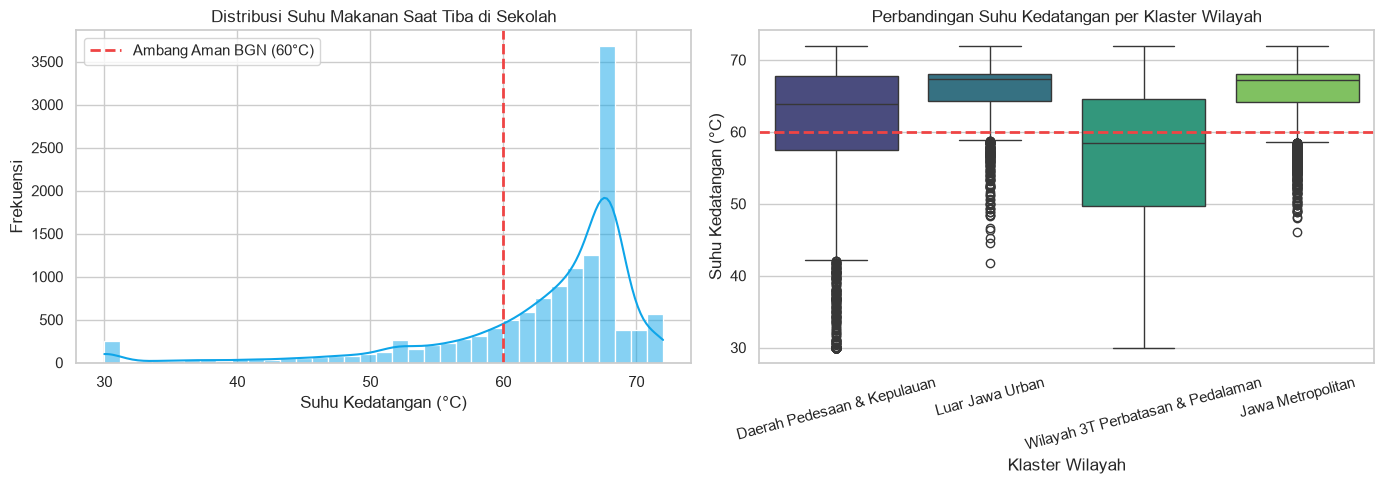

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["food_arrival_temperature_celsius"], bins=35, kde=True, color="#0ea5e9", ax=axes[0])
axes[0].axvline(60.0, color="#ef4444", linestyle="--", linewidth=2, label="Ambang Aman BGN (60°C)")
axes[0].set_title("Distribusi Suhu Makanan Saat Tiba di Sekolah")
axes[0].set_xlabel("Suhu Kedatangan (°C)")
axes[0].set_ylabel("Frekuensi")
axes[0].legend()

sns.boxplot(data=df, x="regional_cluster", y="food_arrival_temperature_celsius", hue="regional_cluster", palette="viridis", legend=False, ax=axes[1])
axes[1].axhline(60.0, color="#ef4444", linestyle="--", linewidth=2)
axes[1].set_title("Perbandingan Suhu Kedatangan per Klaster Wilayah")
axes[1].set_xlabel("Klaster Wilayah")
axes[1].set_ylabel("Suhu Kedatangan (°C)")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

# Pemilihan Fitur & Train-Test Split

In [14]:
features = [
    "regional_cluster",
    "province",
    "beneficiary_category",
    "protein_type",
    "delivery_transport_mode",
    "kitchen_daily_capacity_portions",
    "delivery_distance_km",
    "transit_time_minutes"
]

cat_cols = [
    "regional_cluster",
    "province",
    "beneficiary_category",
    "protein_type",
    "delivery_transport_mode"
]

target_temp = "food_arrival_temperature_celsius"
target_spoil = "spoilage_risk_index"

X = df[features]
y_temp = df[target_temp]
y_spoil = df[target_spoil]

X_train, X_test, yt_train, yt_test, ys_train, ys_test = train_test_split(
    X, y_temp, y_spoil, test_size=0.2, random_state=42
)

print(f"Data Latih: {len(X_train):,} baris | Data Uji: {len(X_test):,} baris")

Data Latih: 10,400 baris | Data Uji: 2,600 baris


# Pelatihan Model Random Forest Regressor

In [15]:
def build_pipeline():
    preprocessor = ColumnTransformer(
        transformers=[("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)],
        remainder="passthrough"
    )
    return Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(n_estimators=100, max_depth=16, random_state=42, n_jobs=-1))
    ])

model_temp = build_pipeline()
model_temp.fit(X_train, yt_train)

model_spoil = build_pipeline()
model_spoil.fit(X_train, ys_train)

print("Kedua model Random Forest (100 Trees, max_depth=16) selesai dilatih!")

Kedua model Random Forest (100 Trees, max_depth=16) selesai dilatih!


# Evaluasi Performa Model & Grafik Aktual vs Prediksi

=== EVALUASI MODEL PREDIKSI SUHU KEDATANGAN (°C) ===
R² Score       : 87.72%
Median Error   : ± 1.44 °C
MAE            : 1.99 °C
RMSE           : 2.78 °C

=== EVALUASI MODEL INDEKS RISIKO PEMBUSUKAN (0-10) ===
R² Score       : 96.76%
Median Error   : ± 0.00


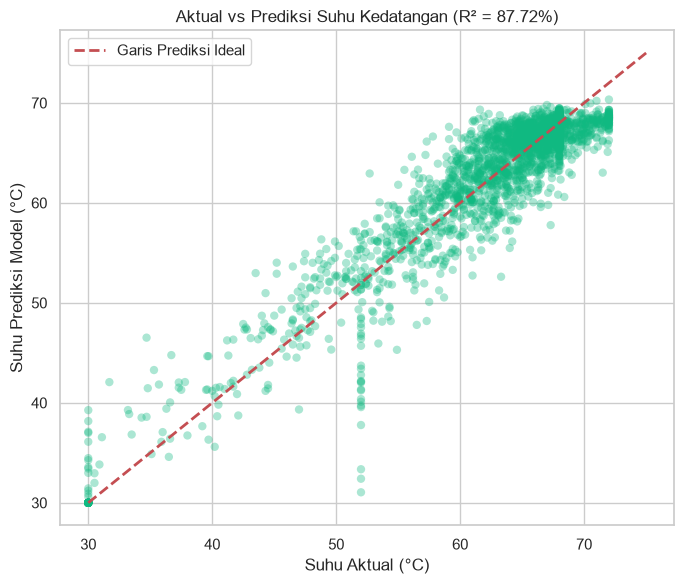

In [16]:
pred_temp = model_temp.predict(X_test)
pred_spoil = model_spoil.predict(X_test)

r2_temp = float(r2_score(yt_test, pred_temp))
medae_temp = float(median_absolute_error(yt_test, pred_temp))
mae_temp = float(mean_absolute_error(yt_test, pred_temp))
rmse_temp = float(root_mean_squared_error(yt_test, pred_temp))

r2_spoil = float(r2_score(ys_test, pred_spoil))
medae_spoil = float(median_absolute_error(ys_test, pred_spoil))

print("=== EVALUASI MODEL PREDIKSI SUHU KEDATANGAN (°C) ===")
print(f"R² Score       : {r2_temp*100:.2f}%")
print(f"Median Error   : ± {medae_temp:.2f} °C")
print(f"MAE            : {mae_temp:.2f} °C")
print(f"RMSE           : {rmse_temp:.2f} °C\n")

print("=== EVALUASI MODEL INDEKS RISIKO PEMBUSUKAN (0-10) ===")
print(f"R² Score       : {r2_spoil*100:.2f}%")
print(f"Median Error   : ± {medae_spoil:.2f}")

plt.figure(figsize=(7, 6))
plt.scatter(yt_test, pred_temp, alpha=0.35, color="#10b981", edgecolors="none")
plt.plot([30, 75], [30, 75], "r--", linewidth=2, label="Garis Prediksi Ideal")
plt.title(f"Aktual vs Prediksi Suhu Kedatangan (R² = {r2_temp*100:.2f}%)")
plt.xlabel("Suhu Aktual (°C)")
plt.ylabel("Suhu Prediksi Model (°C)")
plt.legend()
plt.tight_layout()
plt.show()

# Simpan Artefak Model & Metadata untuk Streamlit

In [17]:
cluster_to_provinces = {
    cluster: sorted(group["province"].unique().tolist())
    for cluster, group in df.groupby("regional_cluster")
}

cluster_stats = (
    df.groupby("regional_cluster")
    .agg(
        mean_temp=("food_arrival_temperature_celsius", "mean"),
        median_temp=("food_arrival_temperature_celsius", "median"),
        mean_spoilage=("spoilage_risk_index", "mean"),
        mean_waste=("plate_waste_percentage", "mean"),
        count=("distribution_id", "count")
    )
    .reset_index()
    .sort_values("mean_temp", ascending=False)
    .to_dict(orient="records")
)

metadata = {
    "features": features,
    "options": {
        "regional_cluster": sorted(df["regional_cluster"].unique().tolist()),
        "cluster_to_provinces": cluster_to_provinces,
        "beneficiary_category": sorted(df["beneficiary_category"].unique().tolist()),
        "protein_type": sorted(df["protein_type"].unique().tolist()),
        "delivery_transport_mode": sorted(df["delivery_transport_mode"].unique().tolist())
    },
    "cluster_stats": cluster_stats,
    "metrics": {
        "total_data": int(len(df)),
        "total_provinces": int(df["province"].nunique()),
        "r2_temp": round(r2_temp * 100, 2),
        "medae_temp": round(medae_temp, 2),
        "r2_spoil": round(r2_spoil * 100, 2),
        "medae_spoil": round(medae_spoil, 2)
    }
}

with open("model/metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

joblib.dump(model_temp, "model/model_suhu_mbg.pkl", compress=3)
joblib.dump(model_spoil, "model/model_spoilage_mbg.pkl", compress=3)

print("✅ File model terkompresi berhasil disimpan di folder model/!")

✅ File model terkompresi berhasil disimpan di folder model/!
